<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/02_pytorch_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### neural network classification with pytorch

* classification is a problem of predicting whether something  is one
thing or another (there can be multiple things as option)


* check the book version of this notebook

## 1. classification data and get in ready


and noise is like it tells how much scaterring of points we need

With random_state=42 → you get the exact same dataset every time

Simple Analogy , that why we use number 42 and it doesnt have a very important meaning .

-> Imagine a shuffled deck of cards:

* random_state=42 → shuffle style #42 → always gives [3, K, 7, A, 9...]
* random_state=7  → shuffle style #7  → always gives [Q, 2, 8, 5, K...]

The number 42 doesn't refer to any position — it just selects which shuffling pattern to use.

In [ ]:
from sklearn.datasets import make_circles

# make 1000 samples
n_samples  = 1000

#create circles
X,y = make_circles(n_samples,
                   noise=0.03,
                   random_state =42)


In [ ]:
len(X), len(y)

(1000, 1000)

In [ ]:
print(f"first 5 samples of X:\n  {X[:5]}")
print(f"first 5 samples of y:\n {y[:5]}")

first 5 samples of X:
  [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
first 5 samples of y:
 [1 1 1 1 0]


head() Shows First N Rows of the Table!  

and X1 there is that i shows first column and and X2 shows the second colum

In [ ]:
# make datframe of circle data
import pandas as pd
# DataFrame() creates the table
# Dataframe() It takes your raw data and organizes it into a neat rows & columns table (like Excel)
circles  =pd.DataFrame({"X1" : X[:,0], # 1st coordinate of all points , har ek point ka x cordinate
                        "X2" : X[:,1], # 2nd coordinate of all points , har ek point ka y cordinate
                        "label" :  y}) # 0 or 1 for each point
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


In [ ]:
circles.label.value_counts()

,count
label,
1,500
0,500


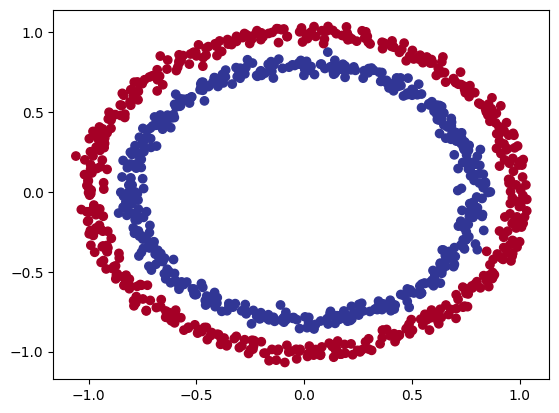

In [ ]:
# visualize , visualize , visualize
import matplotlib.pyplot as plt
# plt.scatter() - Creates a scatter plot — plots individual points on a graph
plt.scatter(x= X[:,0],
            y =X[:,1],
            c= y,  # means: use label values (0 or 1) to decide color
            cmap= plt.cm.RdYlBu);


# so, if point has y=0  →  c=0  →  Red ,  if point has y=1  →  c=1  →  Blue

### check out the scikit-learn

note: tha data we are working with is often refeed as a toy datset that is small enough to experiment but still sizeable enough to practice the fundamnetals.

### 1.1 check input and output shapes

In [ ]:
X.shape , y.shape

((1000, 2), (1000,))

In [ ]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]])

In [ ]:
# view the first example fo features and labels
X_sample = X[0]
y_sample =y[0]

print(f"values for one sample of x: {X_sample} and the same for y : {y_sample}")
print(f"shapes for one sample of X: {X_sample.shape} amd the same for y:{y_sample.shape} ")

values for one sample of x: [0.75424625 0.23148074] and the same for y : 1
shapes for one sample of X: (2,) amd the same for y:() 


### 1.2turn data into tensors and create and test splits

In [ ]:
import torch
import numpy as np
torch.__version__

'2.11.0+cpu'

In [ ]:
type(X)

numpy.ndarray

In [ ]:
# turn data into tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
type(X), X.dtype, y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [ ]:
# split data into training and test sets
from sklearn.model_selection import train_test_split

X_train , X_test, y_train, y_test = train_test_split( X
                                                     ,y
                                                     ,test_size = 0.2 # 0.2  = 20 percent of data will be test
                                                     ,random_state =42 )

In [ ]:
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

## 2. building  a model
lets build a model to classify our blue and red dots

to do so , we want to :
1. setup device agnositic code so our code will run on accelerator (GPU) if there is one
2. construct a model(by sublcasing nn.module)
3. define a loss function and optimize
4. create a training and test loop

In [ ]:
# import pytorch and nn
import torch
from torch import nn

# make device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

now we have setup device agnostic code lets create a model that

1. subclass nn.module (almost all models in pytorch subclass nn.module)

2. create nnlinear() layers that are capable of handling the shapes of our data

3. defines a forward() method that outlines the forward pass (or forward computation) of the model

4. instatiate an instance of our model class and sent it to the target device


In [ ]:
# construct a model that subcass nn.module
class CircleModelV0(nn.Module):
  def __init__ (self):
    super().__init__()
    # create 2 nn.linear layers capable of handling the shapes of our data
    #self.layer_1 = nn.Linear(in_features=2 ,out_features= 5 )# takes in 2 features and upscale 5 features
    #self.layer_2 = nn.Linear(in_features=5 , out_features = 1)# takes in 5 features from preious layer and output a single feature (same shape as y )

    self.two_linear_layers = nn.Sequential(
        nn.Linear(in_features=2 , out_features = 5) ,
        nn.Linear(in_features= 5 , out_features = 1)
    )

    # 3 . define a forward() method that outlines the forward pass
    def forward(self, x):
     # return self.layer_2(self.layer_1(x)) # x-> layer 1 -> layer 2 -> output
       return self.two_linear_layers(x)
# 4. instantiate an instance of our mmodel class and send it to the target device

model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (two_linear_layers): Sequential(
    (0): Linear(in_features=2, out_features=5, bias=True)
    (1): Linear(in_features=5, out_features=1, bias=True)
  )
)

nn.sequnetial () - It's a container that runs layers one by one in order

https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.91139&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false

In [ ]:
device

'cpu'

In [ ]:
# lets replicate the model above using nn.Sequential
model_0 =  nn.Sequential(
    nn.Linear(in_features = 2, out_features = 5),
    nn.Linear(in_features  =5 , out_features = 1)
).to(device)

model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.3982, -0.6281],
                      [-0.4487, -0.6842],
                      [ 0.4017, -0.1365],
                      [-0.4522, -0.4662],
                      [ 0.1905, -0.5812]])),
             ('0.bias', tensor([ 0.0564,  0.7039, -0.0553, -0.4327,  0.3067])),
             ('1.weight',
              tensor([[ 0.0498,  0.2667, -0.1546, -0.2318,  0.1190]])),
             ('1.bias', tensor([0.3977]))])

In [ ]:
# Make predicitions
with torch.inference_mode():
  untrained_preds = model_0(X_test.to(device))
print(f"length of predictions: {len(untrained_preds)}, Shape :{untrained_preds.shape}") # here its 200 points and one predicitons for each ( 0 or 1 )
print(f" length of test samples : {len(X_test)}, Shape: {X_test.shape}    ") # so this is 200 points with 2 coordinates with each x1 and x2
print(f"\n First 10 predictions : \n {torch.round(untrained_preds[:10])  }")
print(f"\n first 10 labels : \n {y_test[:10]}")

length of predictions: 200, Shape :torch.Size([200, 1])
 length of test samples : 200, Shape: torch.Size([200, 2])    

 First 10 predictions : 
 tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]])

 first 10 labels : 
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [ ]:
X_test[:10], y_test[:10]

(tensor([[-0.3752,  0.6827],
         [ 0.0154,  0.9600],
         [-0.7028, -0.3147],
         [-0.2853,  0.9664],
         [ 0.4024, -0.7438],
         [ 0.6323, -0.5711],
         [ 0.8561,  0.5499],
         [ 1.0034,  0.1903],
         [-0.7489, -0.2951],
         [ 0.0538,  0.9739]]),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]))

### 2.1 setup loss function and optimizer

which loss function or optimizer should u use ?

again.. this is problem specific


for example for regression you might want MAE or MSE (mean absolute  error or mean squared error )


for classification you might want binary cross entropy or categorical (cross entropy)

as a reminder the loss function how wrong ur model  predictions are


and for optimizer , two of the most  common and usefull are SGD  and Adam , however pytorch has many built- in -optiions .

* for thr loss function we are going to use `torch.nn.BECWithLogitsLoss()` , for more on what binary cross entropt(BCE) is,

check out the book version or on pytorch about optimizer and loss functions


What is the binary cross-entropy?

* ANS ->

Binary cross-entropy is a handy loss function used in binary classification tasks to measure how well the predicted probabilities align with the true binary labels. It quantifies the dissimilarity between the predicted probabilities and the actual labels, giving us a sense of how accurate the model's predictions are

https://towardsdatascience.com/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a/

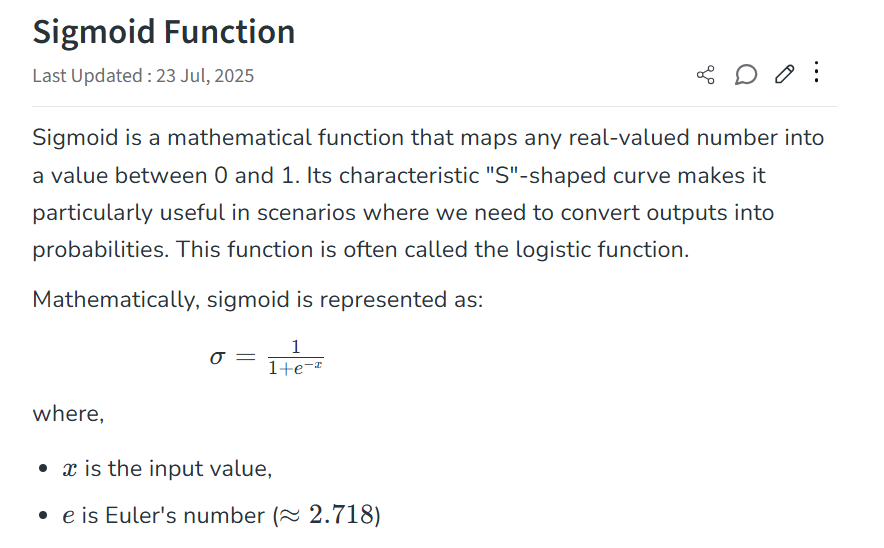

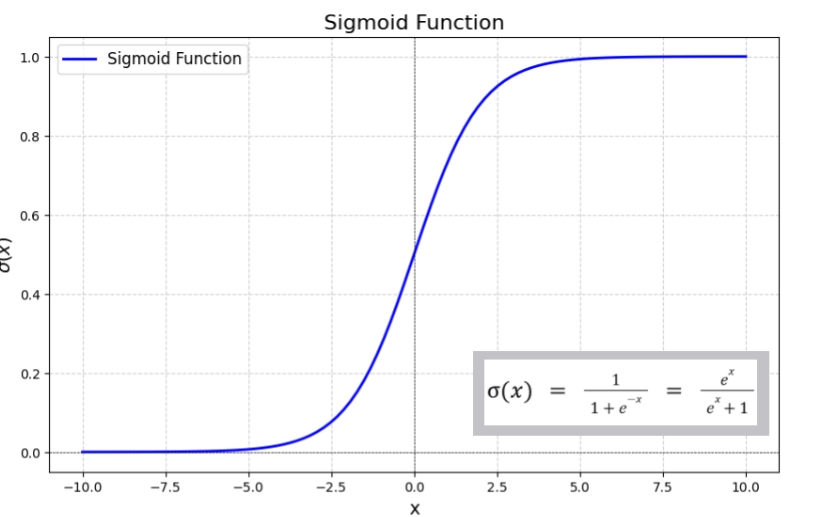

In [ ]:
# setup the loss function
# loss_fn = nn.BCELoss() # BCELoss - requires inputs to have gone through sigmoid activation function prior to input to BCELoss
#nn.Sequential(
    #nn.Sigmoid(),
    #nn.BCEloss())

loss_fn = nn.BCEWithLogitsLoss() # BCEWithLogitLoss = sigmoid activation function built-in
optimizer = torch.optim.SGD(params =model_0.parameters(),
                            lr =0.1)

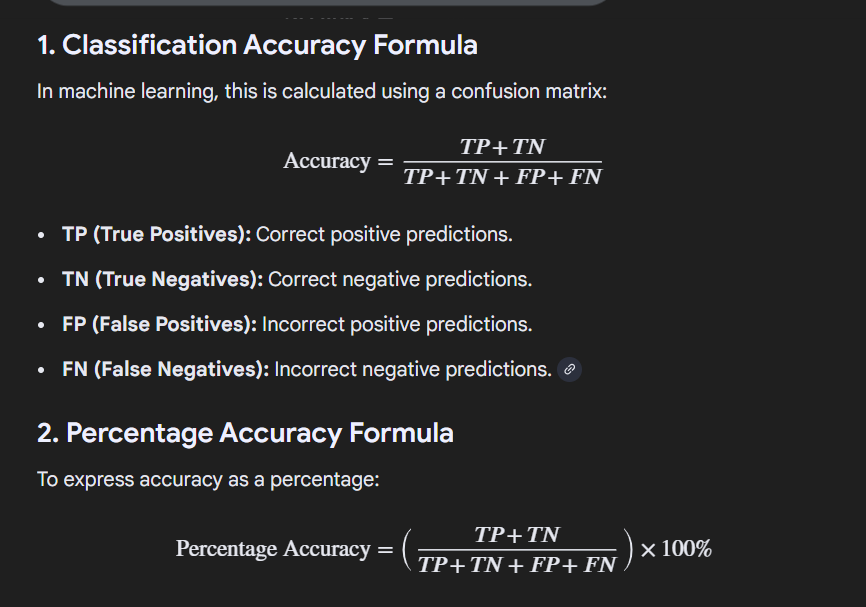

In [ ]:
# calculate accuracy - out of 100 examples , what percentage does our model get right ?
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true , y_pred).sum().item()
  acc = (correct/len(y_pred))*100
  return acc

## 3. train model

to train a model , we need to build a a training loop

1. forward pass
2. calculate the loss
3. optimizer the zero grad
4. loss backward (backpropagation)
5. optimizer step (gradient desent)

### 3.1 going from raw logits -> prediction probabilities  -> predicition labels

Our models outputs are going to be raw  ** logits** ,


We can conver these logits into predicitions probablities by passing them to soem kind of activation function (e.g. sigmoid for binary classification and softmax for multiclass classification )


Then we can conver tour model predcition probabilities  to predicition labels by either rounding them or taking the argmax()

In [ ]:
# view the firs 5 outputs of the forward pass on the test data
model_0.eval()
with torch.inference_mode():
 y_logits = model_0(X_test.to(device))[:5]
y_logits

tensor([[0.6565],
        [0.5849],
        [0.8341],
        [0.6062],
        [0.8181]])

In [ ]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [ ]:
# use the sigmoid activiation function on our model logits to turn them into prediction probbalities
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.6585],
        [0.6422],
        [0.6972],
        [0.6471],
        [0.6938]])

For our prediction probbaility values , we need to perform a range- style rounding on them

* y_pred_probs >= 0.5 , y=1 (class 1)
* y_pred_probs < 0.5 , y = 0 (class 0)

In [ ]:
#find the predicted labels
y_preds = torch.round(y_pred_probs)

# in full (logit-> pred probs -> pred labels)
y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device)[:5])))


# check for equality
print(torch.eq(y_preds.squeeze() , y_pred_labels.squeeze () ))

# get rid of extra dimension
y_preds.squeeze()

tensor([True, True, True, True, True])


tensor([1., 1., 1., 1., 1.])

In [ ]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

### 3.2 builiding a training a loop



* One complete pass through ALL training data = 1 epoch

 * Forward Pass (predict)   +  Backward Pass   (learn) =  1 Epoch
     

* Loss goes down ⬇️ and Accuracy goes up ⬆️ each epoch!

In [ ]:
torch.manual_seed(42)


# set the number of epochs
epochs  = 1000

# put data to target device
X_train , y_train  = X_train.to(device) , y_train.to(device)
X_test, y_test = X_test.to(device) , y_test.to(device)

# build training and evalution loop
for epoch in range (epochs):
  ### training
  model_0.train()

  # !. forward pass
  y_logits = model_0(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits)) # turn logtits -> pred probs -> pred labels

  #2. calculate loss accuracy
  #loss = loss_fn(torch.sgmoid(y_logits), # nn.BCELoss expects predictions probablities as input
                 #(y_train))

  loss  = loss_fn(y_logits, # nn.BCEWithLogitsLoss  expects raw logits as input
                  y_train)

  acc = accuracy_fn(y_true = y_train ,
                   y_pred = y_pred)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. loss backward (backpropagation)
  loss.backward()

  # 5. optimizer step(gradient descent )
  optimizer.step()

  ### testing
  model_0.eval()
  with torch.inference_mode():
    # 1. forward pass
    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    # 2.calculate test loss/acc
    test_loss = loss_fn(test_logits,
                        y_test)
    test_acc = accuracy_fn(y_true =y_test,
                           y_pred =test_pred)

    # print out whats happenin
    if epoch % 10 == 0:
      print(f"epoch : {epoch} | loss : {loss:.5f}, Acc: {acc:.2f}%, | test loss : {test_loss:.5f} | test acc: {test_acc:.2f}%")





epoch : 0 | loss : 0.76173, Acc: 50.00%, | test loss : 0.74883 | test acc: 50.00%
epoch : 10 | loss : 0.71949, Acc: 50.00%, | test loss : 0.71500 | test acc: 50.00%
epoch : 20 | loss : 0.70352, Acc: 50.00%, | test loss : 0.70267 | test acc: 50.00%
epoch : 30 | loss : 0.69728, Acc: 50.00%, | test loss : 0.69810 | test acc: 50.00%
epoch : 40 | loss : 0.69479, Acc: 50.00%, | test loss : 0.69642 | test acc: 50.00%
epoch : 50 | loss : 0.69379, Acc: 50.12%, | test loss : 0.69579 | test acc: 50.00%
epoch : 60 | loss : 0.69337, Acc: 54.75%, | test loss : 0.69555 | test acc: 49.50%
epoch : 70 | loss : 0.69320, Acc: 52.25%, | test loss : 0.69544 | test acc: 49.50%
epoch : 80 | loss : 0.69312, Acc: 52.00%, | test loss : 0.69536 | test acc: 47.50%
epoch : 90 | loss : 0.69308, Acc: 52.00%, | test loss : 0.69530 | test acc: 49.00%
epoch : 100 | loss : 0.69306, Acc: 51.25%, | test loss : 0.69524 | test acc: 47.50%
epoch : 110 | loss : 0.69305, Acc: 51.50%, | test loss : 0.69519 | test acc: 47.50%
epo

## 4. make predictions  and evaluate the  model

* from the metrics it looks like our model isnt learning anythign

* so to inspect it lets make some predictions and make them visual!

* in other words , visualize , visualize, visualize

*to do so we are going to import a fucntion  called plot_decision_boundart()

https://madewithml.com/courses/foundations/neural-networks/

In [ ]:
import requests
from pathlib import Path
# download helper function from learn pytorch repo (if its not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py" , "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

downloading helper_functions.py


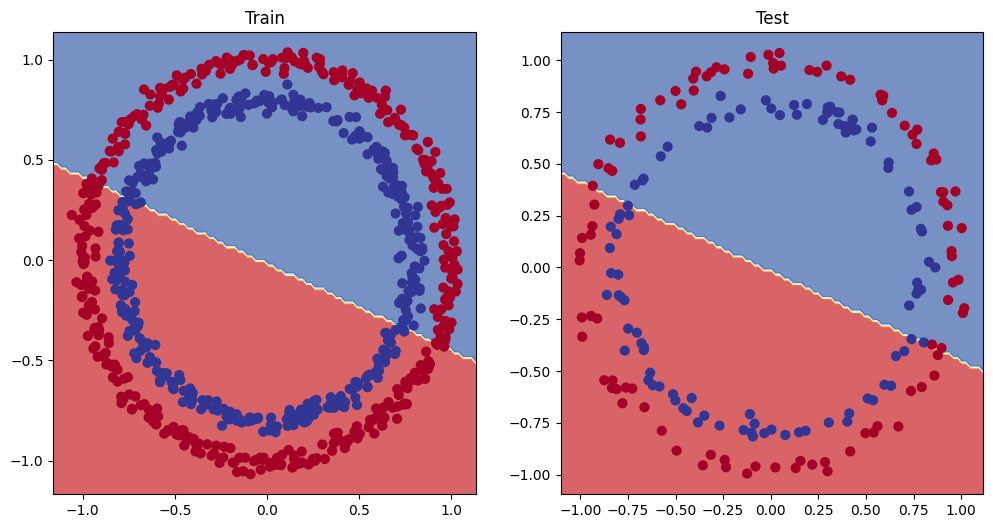

In [ ]:
# plot decision boundary of the modle
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)

plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

### 5. improvin a model  (from a model perspective)

* add more layers - give the model more chances to learna about patterns in the data

* add more hidden units - go from 5 hidden units to 10 hidden units

* fit for longer

* changing the activation functions

* change the learning rate

* change the loss function

these options are all from a model perspective because they deal firectly with the model rather than the data

and because these options arre all values we (as machine learning an enginners and data scientists ) can change , they are referred as hyperparameters .

lets try and improve our model by:

* adding more hidden units: 5-> 10
* increase the number of layers:2 -> 3
* increase the number of epochs : 100 -> 1000

In [ ]:
class CircleModelV1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features = 2, out_features =10)
    self.layer_2 = nn.Linear(in_features = 10, out_features =10)
    self.layer_3 = nn.Linear(in_features = 10, out_features =1)

  def forward(self, x):
    z = self.layer_1(x)
    z = self.layer_2(z)
    z = self.layer_3(z)
    return z
    #return self.layer_3(self.layer_2)(self.layer_1(x)) # this way of writing operations leverages speed ups where possible the behind the scenes

model_1 = CircleModelV1().to(device)
model_1


CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
model_1.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188],
                      [ 0.6146,  0.1323],
                      [ 0.5224,  0.0958],
                      [ 0.3410, -0.0998],
                      [ 0.5451,  0.1045],
                      [-0.3301,  0.1802]])),
             ('layer_1.bias',
              tensor([-0.3258, -0.0829, -0.2872,  0.4691, -0.5582, -0.3260, -0.1997, -0.4252,
                       0.0667, -0.6984])),
             ('layer_2.weight',
              tensor([[ 0.2856, -0.2686,  0.2441,  0.0526, -0.1027,  0.1954,  0.0493,  0.2555,
                        0.0346, -0.0997],
                      [ 0.0850, -0.0858,  0.1331,  0.2823,  0.1828, -0.1382,  0.1825,  0.0566,
                        0.1606, -0.1927],
                      [-0.3130, -0.1222, -0.2426,  0.2595,  0.0911,  0.1

In [ ]:
# create a loss function
loss_fn = nn.BCEWithLogitsLoss()

# create an optimizer
optimzer = torch.optim.SGD(params = model_1.parameters(),
                           lr =0.1)

* model_0.train() ->  # training mode
* model_0.eval()  ->  # testing/evaluation mode

* eval() Switches Model to Testing Mode!

In [ ]:
# write a training and evalutation loop for model_1
torch.manual_seed(42)
torch.cuda.manual_seed(42)


#train for longer
epochs = 1000

# put data on the target device
X_train , y_train = X_train.to(device) , y_train.to(device)
X_test , y_test  = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
  ### training
  model_1.train()

  # 1. forward pass
  y_logits = model_1(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits)) # logits ->  predicts probabilities

  # 2. calculate the loss/acc
  loss = loss_fn(y_logits ,y_train)
  acc = accuracy_fn(y_true = y_train,
                    y_pred = y_pred)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. loss backward (backpropagation)
  loss.backward()

  # 5. optimizer step (gradient desecnt)
  optimizer.step()

  ### testing
  model_1.eval()
  with torch.inference_mode():
    # 1 forward pass
    test_logits = model_1(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    # 2 calculate loss
    test_loss = loss_fn(test_logits,
                        y_test)

    test_acc = accuracy_fn(y_true= y_test,
                            y_pred = test_pred)

    # print out what's happening
    if epoch % 100 == 0 :
      print(f" Epoch : {epoch}  | Loss : {loss:.5f}, Acc : {acc:.2f}% | test loss: {test_loss:.5f} , test acc: {test_acc:.2f}%    ")



 Epoch : 0  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 100  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 200  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 300  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 400  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 500  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 600  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 700  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 800  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    
 Epoch : 900  | Loss : 0.69396, Acc : 50.88% | test loss: 0.69261 , test acc: 51.00%    


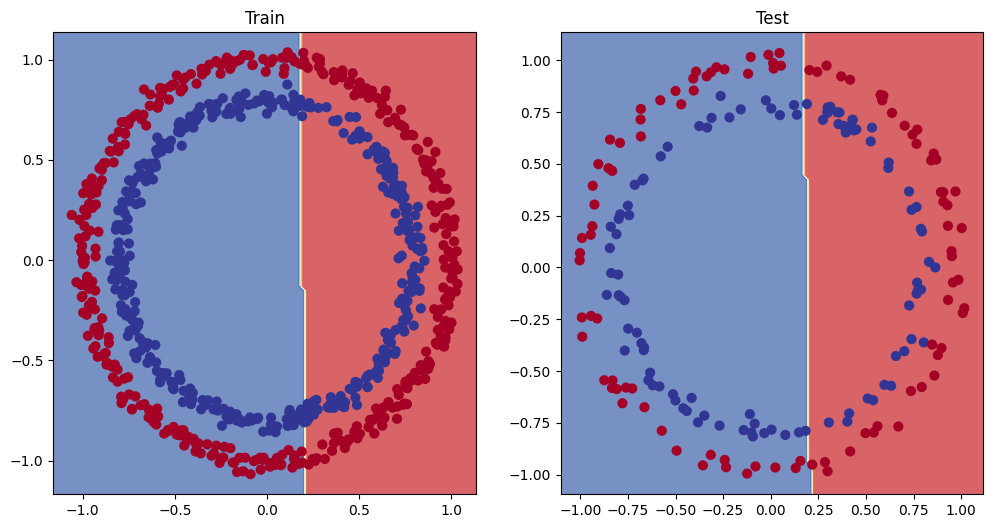

In [ ]:
# plot decision boundary of the modle
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)

plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

### 5.1  preparing data to see if our  model can fit a straught lin e

one way to troubleshoot to a larger problem is to test out a smaller problem

In [ ]:
# create some data (same as notebook 01)
weight = 0.7
bias = 0.3
start = 0
step = 0.01
end = 1

# create data
X_regression = torch.arange(start, end , step ).unsqueeze(dim=1)
y_regression = weight * X_regression + bias # liner regression formula without epsilon

# check the data
print(len(X_regression))
X_regression[:5], y_regression[:5]

100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [ ]:
#create train and test split
train_split = int(0.8 * len(X_regression))
X_train_regression , y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression , y_test_regression = X_regression[train_split:] , y_regression[train_split:]

# check the lengths of each
len(X_train_regression), len(X_test_regression), len(y_train_regression), len(y_test_regression)



(80, 20, 80, 20)

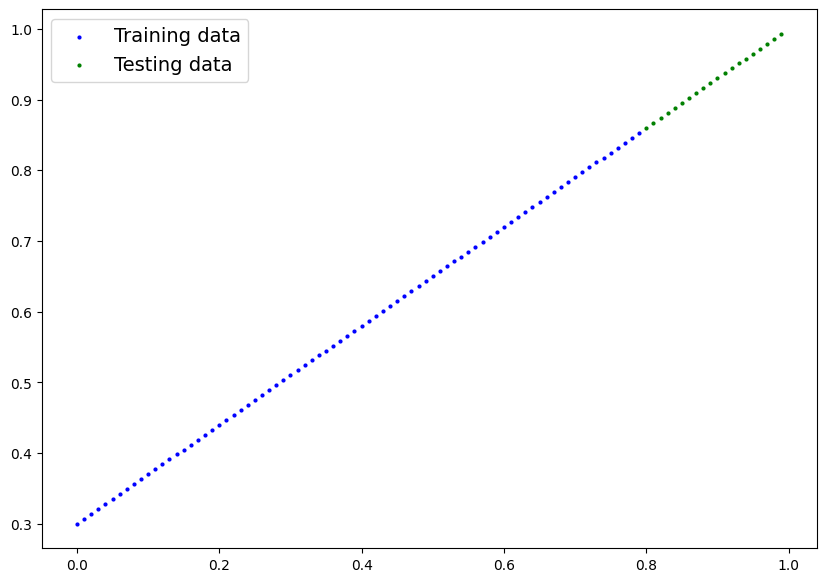

In [ ]:
plot_predictions(train_data = X_train_regression,
                 train_labels = y_train_regression,
                 test_data = X_test_regression,
                 test_labels = y_test_regression)


In [ ]:
X_train_regression[:10], y_train_regression[:10]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400],
         [0.0500],
         [0.0600],
         [0.0700],
         [0.0800],
         [0.0900]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280],
         [0.3350],
         [0.3420],
         [0.3490],
         [0.3560],
         [0.3630]]))

### 5.2 adjusting `model_1` to fit a straight line

In [ ]:
# same architecture as model_1 (but using nn.sequential())
model_2 = nn.Sequential(
    nn.Linear (in_features = 1 , out_features = 10),
    nn.Linear (in_features = 10 , out_features = 10),
    nn.Linear (in_features= 10 , out_features = 1)
).to(device)

model_2


Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
# loss and optimizer
loss_fn = nn.L1Loss() # MAE loss with regression data
optimizer = torch.optim.SGD(params = model_2.parameters(),
                           lr = 0.01)

In [ ]:
# check this in a new cell!
print(X_train_regression.dtype)  # probably float64
print(y_train_regression.dtype)  # probably float64

torch.float32
torch.float32


In [ ]:
# train the model
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# set the number of epochs
epochs =1000

# put the data on the target device
X_train_regression, y_train_regression = X_train_regression.to(device), y_train_regression.to(device)
X_test_regression, y_test_regression = X_test_regression.to(device), y_test_regression.to(device)

# training
for epoch in range(epochs):
  y_pred = model_2(X_train_regression)
  loss = loss_fn(y_pred, y_train_regression)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # testing
  model_2.eval()
  with torch.inference_mode():
    test_pred = model_2(X_test_regression)
    test_loss = loss_fn(test_pred , y_test_regression)

  # print out whats happening
  if epoch % 100  == 0:
    print(f" epch {epoch} | loss: {loss:.5f}, test loss : {test_loss:.5f}")



 epch 0 | loss: 0.75986, test loss : 0.91103
 epch 100 | loss: 0.02858, test loss : 0.00081
 epch 200 | loss: 0.02533, test loss : 0.00209
 epch 300 | loss: 0.02137, test loss : 0.00305
 epch 400 | loss: 0.01964, test loss : 0.00341
 epch 500 | loss: 0.01940, test loss : 0.00387
 epch 600 | loss: 0.01903, test loss : 0.00379
 epch 700 | loss: 0.01878, test loss : 0.00381
 epch 800 | loss: 0.01840, test loss : 0.00329
 epch 900 | loss: 0.01798, test loss : 0.00360


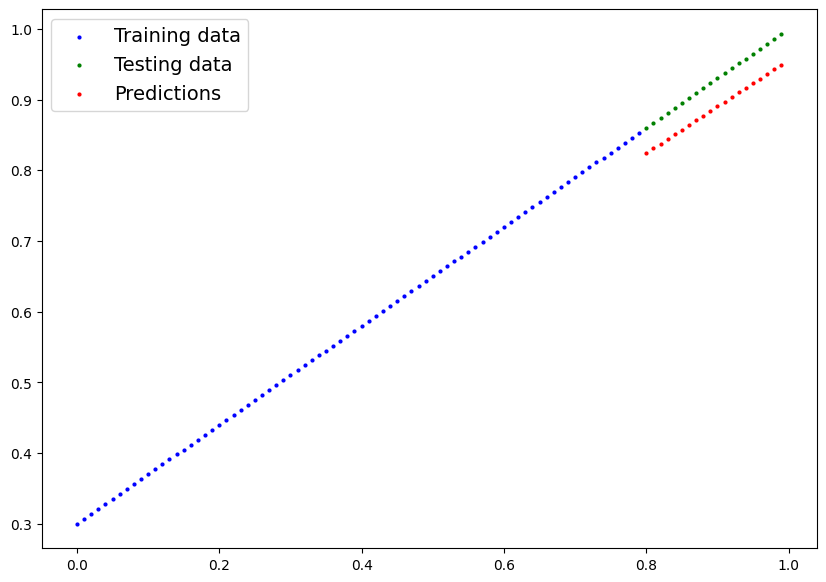

In [ ]:
# turn on  evaluation mode
model_2.eval()

# make predictions (inference)
with torch.inference_mode():
  y_preds = model_2(X_test_regression)

# plot data and predictions
plot_predictions(train_data = X_train_regression.cpu(),
                 train_labels = y_train_regression.cpu(),
                 test_data = X_test_regression.cpu(),
                 test_labels = y_test_regression.cpu(),
                 predictions = y_preds.cpu());



## 6. the missing pice : non - linearity

* what patterns could u draw if u have given an infinte amount of straight and none straight line?

or is machines learning tersm , an infinite (but really it is finite ) of linear and non - linear functions ?



### 6.1 recreating non-linearity data(red and blue circles)

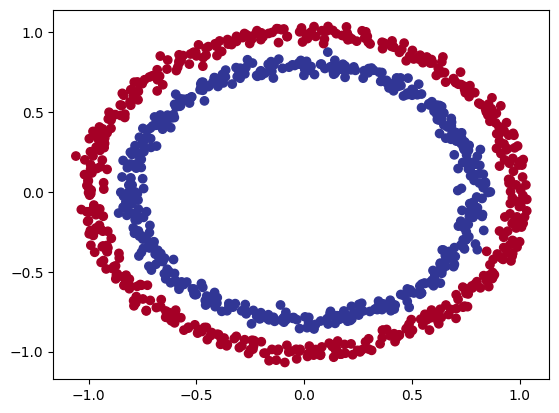

In [ ]:
# make and plot data
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

X,y =make_circles(n_samples,
                  noise = 0.03,
                  random_state = 42)

plt.scatter(X[:, 0],X[:, 1], c = y, cmap = plt.cm.RdYlBu           )

In [ ]:
# convert data into tensors and then to train and test splits
import torch
from sklearn.model_selection import train_test_split

# turn data into tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# split into train and test sets
X_train , X_test , y_train , y_test = train_test_split(X,
                                                       y,
                                                       test_size= 0.2,
                                                       random_state = 42
                                                       )
X_train[:5], y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

### 6.2  building a model with non -linearity

* linear = straight linear
* non-linear = non straight lines

artificial neural networks are a large combination of linear and non linear functions which are potentially able to find the data .

In [ ]:
# build a model with non inear activation function
from torch import nn
class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features = 2 , out_features = 10)
    self.layer_2 = nn.Linear(in_features = 10, out_features = 10)
    self.layer_3 = nn.Linear(in_features = 10, out_features = 1)
    self.relu = nn.ReLU() # relu is non linear activation function
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    # where should we put our non-linear activation functions?
    return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))


model_3 =CircleModelV2().to(device)
model_3

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)

In [ ]:
# setup loss and optimizer
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(),
                            lr = 0.1)

####  some binary classification
* spam or not spam
* credit cards = fraud or not
* insurance claims = at fault or not fault

### 6.3 training our model with non linearity

In [ ]:
len(X_test), len(y_test)

(200, 200)

In [ ]:
# random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# put all data on target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# loop through data
epochs = 1000

for epoch in range(epochs):
  ### training
  model_3.train()

  # 1. forward pass

  y_logits = model_3(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits)) # logits  -> prediction probabilities ->prediction labels

  # 2. calculate the loss
  loss = loss_fn(y_logits , y_train) # BCEWithLogits (takes in logits as first input)
  acc = accuracy_fn(y_true = y_train,
                     y_pred = y_pred)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4.loss backward()
  loss.backward()

  # 5. step the optimizer
  optimizer.step()

  ### testing
  model_3.eval()

  with torch.inference_mode():
    test_logits = model_3(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_test )
    test_acc = accuracy_fn (y_true = y_test,
                            y_pred = test_pred)

    # print out what is happening
    if epoch % 100 == 0:
      print(f"epoch : {epoch} | loss: {loss:.4f}, Acc: {acc:.2f}% | test_loss : { test_loss:.4f} , test acc: {test_acc:.2f}%     ")



epoch : 0 | loss: 0.6929, Acc: 50.00% | test_loss : 0.6932 , test acc: 50.00%     
epoch : 100 | loss: 0.6912, Acc: 52.88% | test_loss : 0.6910 , test acc: 52.50%     
epoch : 200 | loss: 0.6898, Acc: 53.37% | test_loss : 0.6894 , test acc: 55.00%     
epoch : 300 | loss: 0.6879, Acc: 53.00% | test_loss : 0.6872 , test acc: 56.00%     
epoch : 400 | loss: 0.6852, Acc: 52.75% | test_loss : 0.6841 , test acc: 56.50%     
epoch : 500 | loss: 0.6810, Acc: 52.75% | test_loss : 0.6794 , test acc: 56.50%     
epoch : 600 | loss: 0.6751, Acc: 54.50% | test_loss : 0.6729 , test acc: 56.00%     
epoch : 700 | loss: 0.6666, Acc: 58.38% | test_loss : 0.6632 , test acc: 59.00%     
epoch : 800 | loss: 0.6516, Acc: 64.00% | test_loss : 0.6476 , test acc: 67.50%     
epoch : 900 | loss: 0.6236, Acc: 74.00% | test_loss : 0.6215 , test acc: 79.00%     


### 6.4 evaluating a model trained with non- linear activation fucntions



In [ ]:
# make predictions
model_3.eval()
with torch.inference_mode():
  y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10] , y_test[:10]

(tensor([1., 0., 1., 0., 0., 1., 0., 0., 1., 0.]),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]))

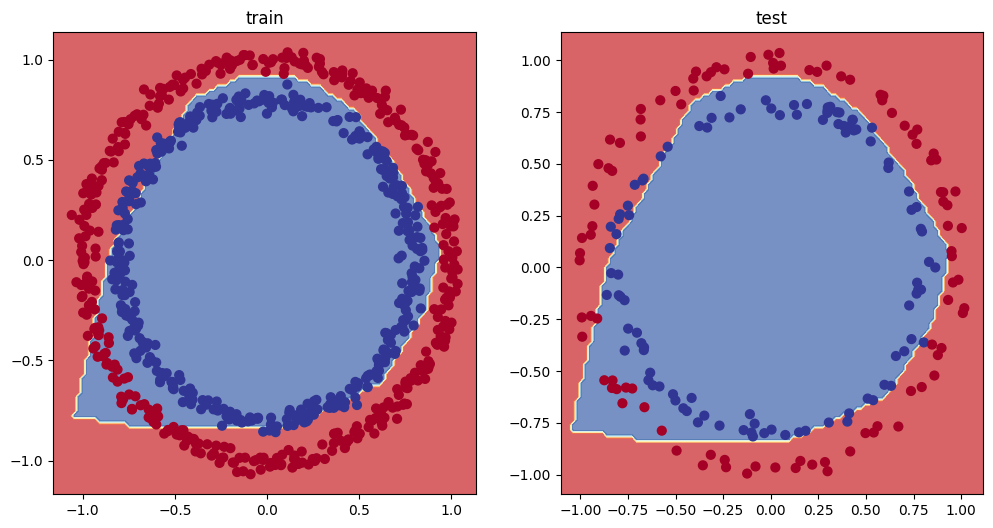

In [ ]:
# plot decision boundaries
plt.figure(figsize = (12,6))
plt.subplot(1,2,1)
plt.title("train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1,2,2)
plt.title("test")
plot_decision_boundary(model_3 , X_test , y_test)


## 7. replicate non - linear activation function  

* Neural network rather than us  telling the model what to learn , we give it the tools to discover patterns in data and it tries and it tries to figure out the patterns on its own .


and these tools are linear and non linear functions.

In [ ]:
# create a tensor
A = torch.arange (-10, 10, 1 , dtype =torch.float32)
A.dtype

torch.float32

In [ ]:
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

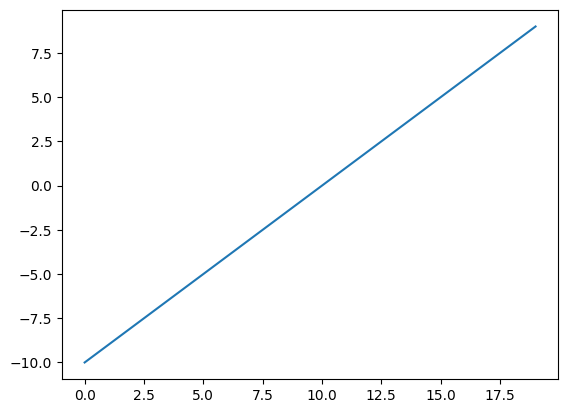

In [ ]:
# visualize the tensor
plt.plot(A);

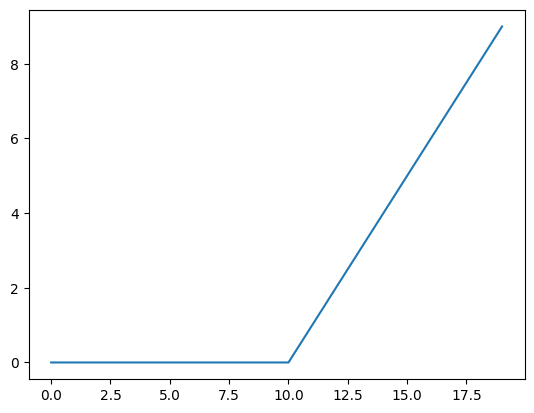

In [ ]:
plt.plot(torch.relu(A))

In [ ]:
def relu(x): # torch.Tensor:
  return torch.maximum(torch.tensor(0), x) # inputs must be tensors

relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

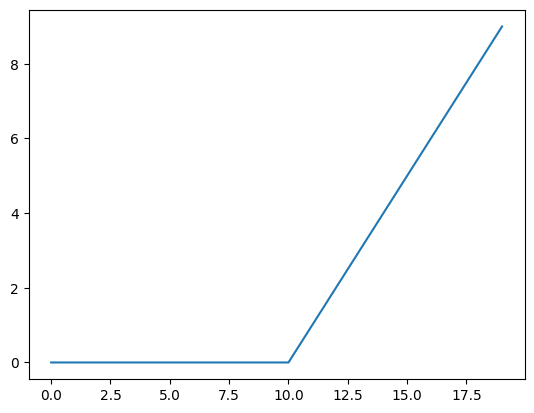

In [ ]:
# plot relu activation function
plt.plot(relu(A))

In [ ]:
# now lets do the same for sigmoid
def sigmoid (x):
  return 1/ (1 + torch.exp(-x))


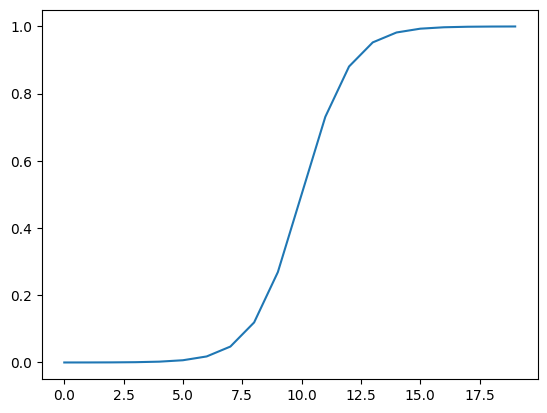

In [ ]:
plt.plot(torch.sigmoid(A))

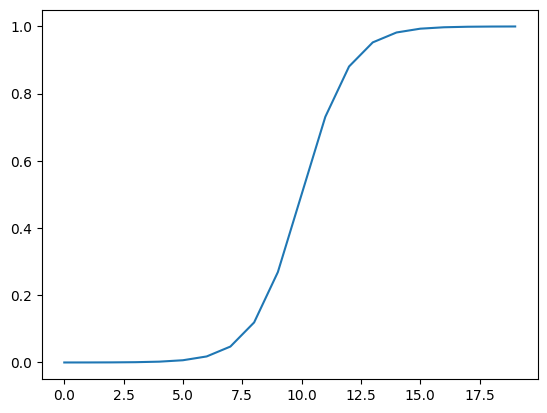

In [ ]:
plt.plot(sigmoid(A))

### 8. putting it all together with a multi class classification problem

* binary classification = one thing or another (cat vs dog , spam vs not spam , fraud or not )

* multiclass classification = more than one thing or another (cat vs dog vs chicken )

### 8.1 creating a toty multi class dataset


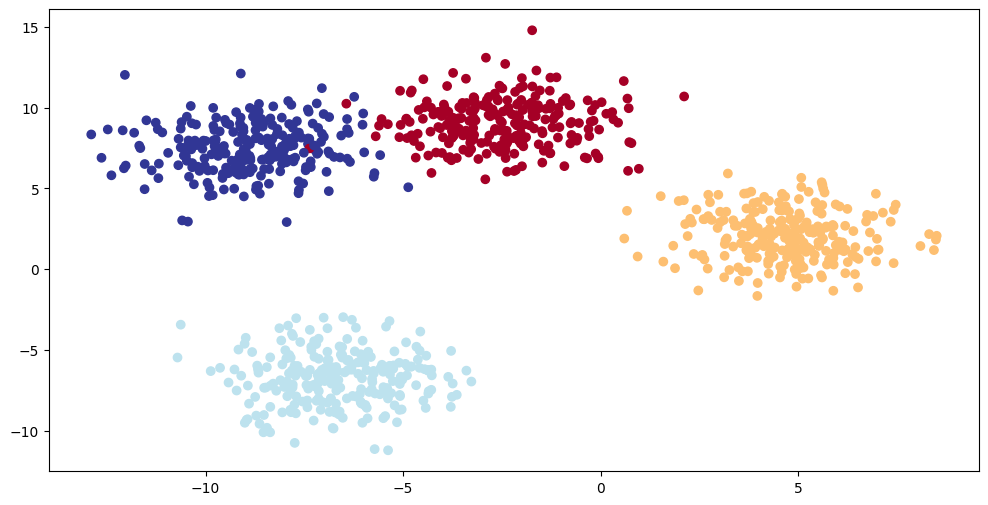

In [ ]:
# import dependecies
import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs # https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html
from sklearn.model_selection import train_test_split

# set the hyperparamaters for data creation
NUM_CLASSES = 4
NUM_FEATURES= 2
RANDOM_SEED = 42


# 1. create multiclass data
X_blob , y_blob = make_blobs (n_samples = 1000,
                              n_features = NUM_FEATURES,
                              centers = NUM_CLASSES,
                              cluster_std = 1.5 ,  # give the clusters a little shake up,
                              random_state = RANDOM_SEED
                              )
# 2. Turn data into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

# 3. split into train and test
X_blob_train , X_blob_test , y_blob_train , y_blob_test = train_test_split(X_blob,
                                                                           y_blob,
                                                                           test_size = 0.2,
                                                                           random_state = RANDOM_SEED
                                                                           )
# 4. plot data visualize , visualize
plt.figure(figsize = (12,6))
plt.scatter(X_blob[:, 0] , X_blob[:, 1], c =y_blob , cmap = plt.cm.RdYlBu)

### 8.2 building a multi class classification model in pytorch

In machine learning, blob just means a cluster of data points grouped together.

In [ ]:
# create device agnostic cpde
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
# build a multi - class classification model
class BlobModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units = 8):
    """Initilize multi clss classification model.

    args:
    input features (int): number of inputs fetures to the model
    output features (int): number of output features (number of output classes)
    hidden units(int) : number of hidden unnits between layers , default 8

    returns :

    example

    """
    super().__init__()
    self.Linear_layer_stack = nn.Sequential(
        nn.Linear(in_features = input_features, out_features = hidden_units),
        nn.ReLU(),
        nn.Linear(in_features = hidden_units, out_features = hidden_units),
        nn.ReLU(),
        nn.Linear(in_features = hidden_units, out_features = output_features),
    )

  def forward (self , x ) :
    return self.Linear_layer_stack(x)

# create an instance of blob model and send it to the target device
model_4 = BlobModel(input_features = 2,
                    output_features = 4,
                    hidden_units = 8).to(device)

model_4




BlobModel(
  (Linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [ ]:
X_blob_train.shape , y_blob_train.shape

(torch.Size([800, 2]), torch.Size([800]))

In [ ]:
torch.unique(y_blob_train)

tensor([0, 1, 2, 3])

### 8.3 create a loss function and an optimizer for a multi class classification model



https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html

In [ ]:
# create a loss function for multi class classification  - loss functions measure how wrong our model's predictions are
loss_fn = nn.CrossEntropyLoss()


# create an optimizer or multi - class classification - optimize our modle paramtere to try and reduce the loss
optimizer = torch.optim.SGD(params = model_4.parameters(),
                            lr = 0.1) # lr is a hyper parameter u can change it


### 8.4 getting prediction probabilities for a multi class pytorch model

* in order to evaluate an train and test our mode , we need to convert our model's
outputs (logits) to predictions probabilities and then to prediction labels

logits (raw output of the model )-> pred probs(use `torch.softmax` activation function )
-> pred labels(take the argmax of the prediction probabilities)

In [ ]:
# model output → always raw logits
# then YOU convert:
# logits → softmax → probabilities → argmax → final class

In [ ]:
# lets get soem raw ouput erorr of our model
model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test.to(device))

y_logits[:10]

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834],
        [-0.1497, -1.0617, -0.7107, -0.1645],
        [ 0.1539, -0.2887,  0.1520, -0.0109],
        [-0.2154, -1.1795, -0.9300, -0.2745],
        [ 0.2443, -0.2472,  0.1649,  0.0061],
        [-0.2329, -1.2120, -0.9849, -0.3004]])

In [ ]:
y_blob_test[:10]

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0])

In [ ]:
# convert our model's logit outputs to predction probabilities
y_pred_probs = torch.softmax(y_logits , dim =1)
print(y_logits[:5])
print(y_pred_probs[:5])

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834]])
tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3078, 0.2766, 0.1836, 0.2320],
        [0.3719, 0.1286, 0.1532, 0.3463]])


In [ ]:
# convert our model predicition  probabilities to preddiction labels
y_preds = torch.argmax(y_pred_probs , dim =1)
y_preds

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 3, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 1])

In [ ]:
y_blob_test

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0, 0, 1, 0, 0, 0, 3, 3, 2, 3, 3, 3, 0, 1, 2,
        2, 2, 3, 0, 1, 0, 3, 1, 1, 3, 1, 2, 1, 3, 0, 2, 0, 3, 3, 2, 0, 3, 1, 1,
        0, 3, 1, 0, 1, 1, 3, 2, 1, 1, 3, 2, 2, 0, 3, 2, 2, 0, 0, 3, 3, 0, 0, 3,
        3, 3, 2, 3, 3, 3, 3, 1, 0, 2, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 1, 3, 3, 3,
        1, 0, 3, 2, 0, 0, 3, 0, 2, 3, 1, 0, 3, 2, 1, 1, 0, 2, 2, 3, 0, 0, 1, 2,
        2, 3, 0, 1, 2, 0, 0, 0, 2, 3, 1, 2, 3, 2, 0, 3, 0, 0, 1, 1, 1, 0, 2, 2,
        2, 2, 0, 3, 3, 2, 2, 1, 3, 2, 0, 0, 3, 3, 2, 1, 2, 0, 3, 2, 0, 3, 2, 0,
        2, 2, 2, 0, 3, 1, 1, 1, 1, 1, 3, 1, 0, 2, 2, 1, 2, 2, 0, 1, 2, 2, 0, 0,
        1, 3, 2, 0, 3, 1, 2, 1])

In [ ]:
torch.argmax(y_pred_probs[0])

tensor(1)

### 8.5 create a training loop for multi class pytorch model



In [ ]:
y_blob_train.dtype , y_logits.dtype

(torch.int64, torch.float32)

In [ ]:
y_blob_test.shape , X_blob_test.shape,  test_logits.shape

(torch.Size([200]), torch.Size([200, 2]), torch.Size([200]))

In [ ]:
# fit the multi class to the data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# set the no. of epoch
epochs = 100

#put data to the target device_
X_blob_train, y_blob_train = X_blob_train.to(device) , y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device) , y_blob_test.to(device)

# loop through data
for epoch in range(epochs):
  ## training
  model_4.train()

  y_logits = model_4(X_blob_train)
  y_pred = torch.softmax(y_logits , dim = 1).argmax(dim = 1)

  loss = loss_fn(y_logits, y_blob_train)
  acc = accuracy_fn(y_true  = y_blob_train,
                    y_pred = y_pred)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  ### testing
  model_4.eval()
  with torch.inference_mode():
    test_logits = model_4(X_blob_test)
    test_preds = torch.softmax(test_logits, dim =1).argmax(dim =1)

    test_loss = loss_fn(test_logits, y_blob_test)
    test_acc = accuracy_fn(y_true = y_blob_test,
                           y_pred = test_preds)

    # print out whats happening
    if epoch % 10 == 0:
      print(f"epoch : {epoch} | loss: {loss:.4f} , acc:{acc:.2f}% | test loss : {test_loss:.4f}, test accuracy : {test_acc:.2f}% ")



epoch : 0 | loss: 1.1588 , acc:40.38% | test loss : 1.0755, test accuracy : 48.00% 
epoch : 10 | loss: 0.6448 , acc:96.75% | test loss : 0.6607, test accuracy : 97.50% 
epoch : 20 | loss: 0.4254 , acc:98.50% | test loss : 0.4307, test accuracy : 100.00% 
epoch : 30 | loss: 0.2529 , acc:99.12% | test loss : 0.2451, test accuracy : 99.50% 
epoch : 40 | loss: 0.1123 , acc:99.25% | test loss : 0.1023, test accuracy : 99.50% 
epoch : 50 | loss: 0.0663 , acc:99.25% | test loss : 0.0585, test accuracy : 99.50% 
epoch : 60 | loss: 0.0507 , acc:99.25% | test loss : 0.0429, test accuracy : 99.50% 
epoch : 70 | loss: 0.0430 , acc:99.25% | test loss : 0.0349, test accuracy : 99.50% 
epoch : 80 | loss: 0.0384 , acc:99.25% | test loss : 0.0299, test accuracy : 99.50% 
epoch : 90 | loss: 0.0352 , acc:99.25% | test loss : 0.0266, test accuracy : 99.50% 


### 8.6 making and evaluating predictions with a pytorch multi class model

In [ ]:
# make prediction s
model_4.eval()
with torch.inference_mode():
  y_logits  = model_4(X_blob_test.to(device))

# view the first 10 predictions
y_logits[:10]

tensor([[-0.6249,  5.9860, -7.6323, -8.4470],
        [-2.1738, -6.3750, -3.7202,  3.1203],
        [-3.4102, -3.8958,  3.1567, -2.6119],
        [-1.1505,  4.1962, -3.8472, -4.8820],
        [ 3.7548, -1.3391, -9.1422, -6.9466],
        [-2.8211, -7.5767, -4.2944,  3.7944],
        [-3.0306, -3.3328,  2.7955, -2.1374],
        [ 3.3761, -4.0375, -6.8987, -3.5503],
        [-4.3620, -4.9904,  3.8123, -3.3814],
        [ 3.5012, -3.0281, -7.5401, -4.7064]])

In [ ]:
# go from logits  -> prediction prbabilities
y_pred_probs = torch.softmax(y_logits , dim =1)
y_pred_probs[:10]

tensor([[1.3437e-03, 9.9865e-01, 1.2164e-06, 5.3854e-07],
        [4.9905e-03, 7.4740e-05, 1.0630e-03, 9.9387e-01],
        [1.3985e-03, 8.6060e-04, 9.9463e-01, 3.1073e-03],
        [4.7389e-03, 9.9483e-01, 3.1956e-04, 1.1353e-04],
        [9.9388e-01, 6.0966e-03, 2.4904e-06, 2.2378e-05],
        [1.3372e-03, 1.1504e-05, 3.0644e-04, 9.9834e-01],
        [2.9138e-03, 2.1537e-03, 9.8781e-01, 7.1181e-03],
        [9.9838e-01, 6.0198e-04, 3.4435e-05, 9.7989e-04],
        [2.8147e-04, 1.5016e-04, 9.9882e-01, 7.5044e-04],
        [9.9825e-01, 1.4575e-03, 1.5997e-05, 2.7210e-04]])

In [ ]:
y_blob_test

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0, 0, 1, 0, 0, 0, 3, 3, 2, 3, 3, 3, 0, 1, 2,
        2, 2, 3, 0, 1, 0, 3, 1, 1, 3, 1, 2, 1, 3, 0, 2, 0, 3, 3, 2, 0, 3, 1, 1,
        0, 3, 1, 0, 1, 1, 3, 2, 1, 1, 3, 2, 2, 0, 3, 2, 2, 0, 0, 3, 3, 0, 0, 3,
        3, 3, 2, 3, 3, 3, 3, 1, 0, 2, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 1, 3, 3, 3,
        1, 0, 3, 2, 0, 0, 3, 0, 2, 3, 1, 0, 3, 2, 1, 1, 0, 2, 2, 3, 0, 0, 1, 2,
        2, 3, 0, 1, 2, 0, 0, 0, 2, 3, 1, 2, 3, 2, 0, 3, 0, 0, 1, 1, 1, 0, 2, 2,
        2, 2, 0, 3, 3, 2, 2, 1, 3, 2, 0, 0, 3, 3, 2, 1, 2, 0, 3, 2, 0, 3, 2, 0,
        2, 2, 2, 0, 3, 1, 1, 1, 1, 1, 3, 1, 0, 2, 2, 1, 2, 2, 0, 1, 2, 2, 0, 0,
        1, 3, 2, 0, 3, 1, 2, 1])

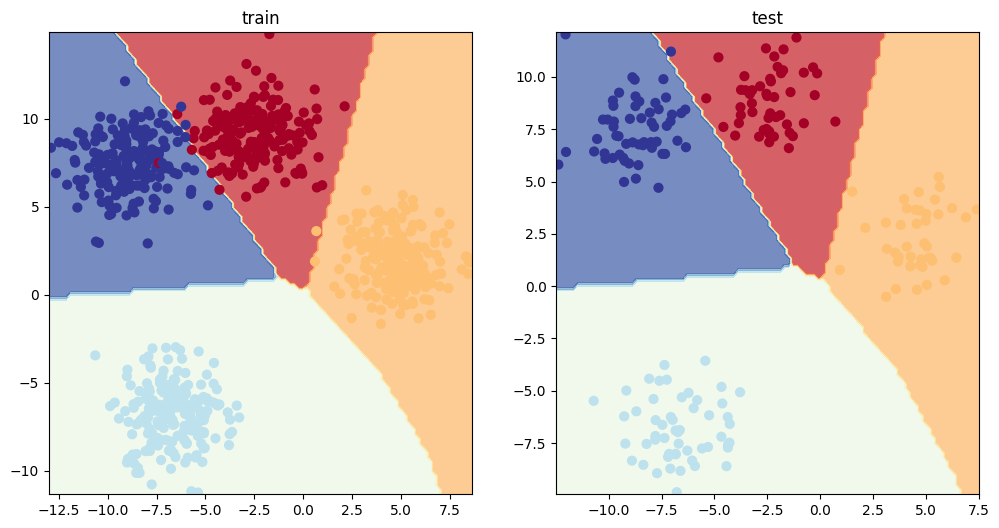

In [ ]:
plt.figure(figsize= (12,6))
plt.subplot(1,2,1)
plt.title("train")
plot_decision_boundary(model_4, X_blob_train , y_blob_train)
plt.subplot(1,2,2)
plt.title("test")
plot_decision_boundary(model_4 , X_blob_test , y_blob_test)

## 9. a few more classification metrics (to evaluate our classification model)

* Accuracy - out of 100 samples , how many doesn't our model
* precision
* recall
* f1 - score
* confusion matrix
* classification report

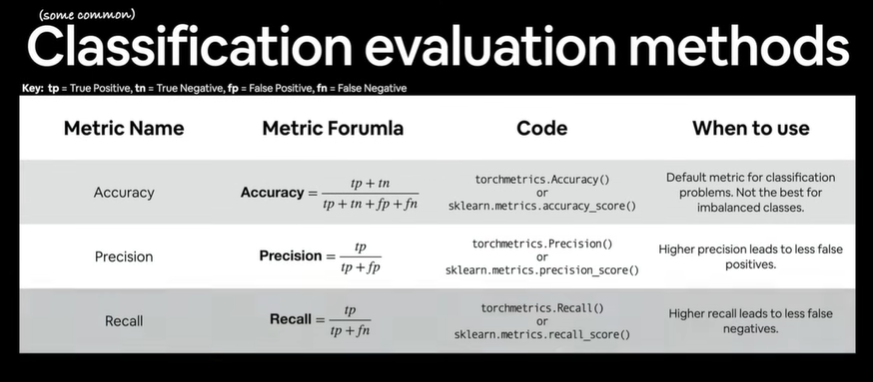

https://pypi.org/project/torchmetrics/

In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 15.3 MB/s eta 0:00:00


In [ ]:
from torchmetrics import Accuracy

# setup matric
torchmetric_accuracy = Accuracy(task="multiclass", num_classes=4).to(device)

# calculating_accuracy
torchmetric_accuracy(y_preds, y_blob_test)

